# Machine Learning aplicado a la predicción de pokemones legendarios

**En este trabajo se presentará una propuesta de aplicación de Machine Learning para "The Complete Pokemon Dataset" en kaggle. La idea de este proyecto es aplicar un algoritmo que permita clasificar pokemones legendarios en base a algunos de los features entregados por el conjunto de datos.**

In [104]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)


font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14) 
matplotlib.rc('ytick', labelsize=14) 
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 300

In [105]:
PokemonSet = pd.read_csv('pokemon.csv')
target = PokemonSet['is_legendary']

## Filtrado de Features

Para que el algoritmo realice un mejor trabajo, filtramos los features que tiene el DataSet. En este caso eliminamos los siguientes features que no aportan información relevante (según criterio propio):
- name
- japanese_name
- pokedex_number
- classification
- against_? 

Además, debido a que abilities es un string que contiene una o más habilidades por pokemones, es una feature un poco más difícil de trabajar, por lo que optamos por eliminarla del DataSet:
- abilities

También eliminamos el feature que nos dice directamente si el pokemon es legendario (pero se utilizará para validar los resultados, por eso se guardo la variable 'y' antes):
- is_legendary

Eliminamos los siguientes 4 features debido a que en el trabajo anterior se determinó que estas están directamente relacionadas con los pokemones legendarios (concentran a los legendarios dentro de unos rangos pequeños), evitando así hacer "trampa" con el modelo y determinar si es que se puede predecir correctamente utilizando las demás features:
- capture_rate
- percentage_male
- base_egg_steps 
- experience_growth

Por último, eliminamos la siguiente feature debido a que es la suma de otras features, por lo que la vuelve redundante para el modelo:
- base_total

In [106]:
PokemonSet = PokemonSet.drop(['name', 
                            'japanese_name', 
                            'pokedex_number',
                            'classfication',
                            'against_fire',
                            'against_water',
                            'against_electric',
                            'against_grass',
                            'against_ice',
                            'against_fight',
                            'against_poison',
                            'against_ground',
                            'against_flying',
                            'against_psychic',
                            'against_bug',
                            'against_rock',
                            'against_ghost',
                            'against_dragon',
                            'against_dark',
                            'against_steel',
                            'against_fairy',
                            'against_normal',
                            'is_legendary',
                            'capture_rate',
                            'percentage_male',
                            'base_egg_steps',
                            'abilities',
                            'experience_growth',
                            'base_total'],
                            axis=1)

PokemonSet

,attack,base_happiness,defense,height_m,hp,sp_attack,sp_defense,speed,type1,type2,weight_kg,generation
0,49,70,49,0.7,45,65,65,45,grass,poison,6.9,1
1,62,70,63,1.0,60,80,80,60,grass,poison,13.0,1
2,100,70,123,2.0,80,122,120,80,grass,poison,100.0,1
3,52,70,43,0.6,39,60,50,65,fire,NaN,8.5,1
4,64,70,58,1.1,58,80,65,80,fire,NaN,19.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
796,101,0,103,9.2,97,107,101,61,steel,flying,999.9,7
797,181,0,131,0.3,59,59,31,109,grass,steel,0.1,7
798,101,0,53,5.5,223,97,53,43,dark,dragon,888.0,7
799,107,0,101,2.4,97,127,89,79,psychic,NaN,230.0,7


Las variables que corresponden a características cualitativas deben de convertirse en valores numéricos para poder ser analizados, así que convertimos las variables 'type1' y 'type2' en una matriz que represente con '1' al tipo de pokemon que si corresponde, y '0' al tipo que no (de esta forma eliminamos los NaN's de la tabla de datos).

In [107]:
tipos = (pd.get_dummies(PokemonSet['type1'], dtype=int)
           .add(pd.get_dummies(PokemonSet['type2'], dtype=int), fill_value=0)
           .astype(int)
           .add_prefix('tipo_'))

PokemonSet = pd.concat([PokemonSet.drop(columns=['type1', 'type2']), tipos], axis=1)

In [108]:
PokemonSet

,attack,base_happiness,defense,height_m,hp,sp_attack,sp_defense,speed,weight_kg,generation,tipo_bug,tipo_dark,tipo_dragon,tipo_electric,tipo_fairy,tipo_fighting,tipo_fire,tipo_flying,tipo_ghost,tipo_grass,tipo_ground,tipo_ice,tipo_normal,tipo_poison,tipo_psychic,tipo_rock,tipo_steel,tipo_water
0,49,70,49,0.7,45,65,65,45,6.9,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
1,62,70,63,1.0,60,80,80,60,13.0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
2,100,70,123,2.0,80,122,120,80,100.0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
3,52,70,43,0.6,39,60,50,65,8.5,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
4,64,70,58,1.1,58,80,65,80,19.0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
796,101,0,103,9.2,97,107,101,61,999.9,7,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
797,181,0,131,0.3,59,59,31,109,0.1,7,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0
798,101,0,53,5.5,223,97,53,43,888.0,7,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
799,107,0,101,2.4,97,127,89,79,230.0,7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


En el caso de los NaN's que se obtienen en la altura y peso, los dejaremos tal cual como están, pues aunque ya sabemos del EDA que este es un error del DataSet debido a que mezcla las características de un pokemon original con alguna variación suya, no queremos modificar mucho los datos que recibimos. De esta manera nos ajustamos mejor a un caso realista en el que podría haber también un error en los datos recolectados.

## Features y Target

De forma final nuestro Target es la predicción de pokemon legendarios y=is_legendary, determinada como '0' para pokemones no legendarios, y como '1' para pokemones legendarios (problema de clasificación con '1' caso verdadero).

Las características que se utilizarán de forma final para la predicción de los pokemones legendarios son las siguientes:

- Stats básicos: attack, defense, hp, sp_attack, sp_defense, speed
- Características únicas: base_happiness, height_m, weight_kg, generación, tipos

La idea de utilizar estos datos es comprobar si los stats y otras características propias y simples de los pokemones son suficientes para determinar si este es legendario o no, eliminando algunas de las features que ya sabemos que están directamente relacionadas con la cualidad de legendario.

# Parte 1: Construcción de un modelo

## Algoritmo seleccionado

Para evaluar este DataSet filtrado se utilizará un modelo de RandomForest de clasificación, de forma que nos podamos ajustar mejor al desbalance de clases (70 pokemones legendarios en un total de 801 pokemones) utilizando trucos de Bagging para aprovechar mejor la información de los pocos legendarios que hay en total.

In [109]:
from sklearn import metrics
from sklearn.model_selection import cross_validate, StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.ensemble import RandomForestClassifier

In [110]:
PokemonSet.shape

(801, 28)

In [ ]:
features = PokemonSet # Como ya filtramos, utilizaremos todas las features actuamente presentes en PokemonSet

In [112]:
model = RandomForestClassifier(random_state=42)

model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

Como la cantidad de pokemones legendarios es poca frente al número total de pokemones, en vez de hacer un train_test_split (que generará grupos con aún menor cantidad de legendarios), utilizaremos un truco de validación anidada, para el cual definiremos un cv_outer (conjunto de prueba que no participa en el entrenamiento ni en la selección de hiperparámetros por fold) y cv_inner (conjunto de validación que compara combinaciones de hiperparámetros por fold), donde los datos restantes de cada fold se utilizarán como entrenamiento.

Este truco evitará que tanto el entrenamiento como la selección de hiperparámetros sea 'inflada' por la combinación entre train y test.

In [113]:
cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
cv_outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)

In [114]:
scoring = {'f1': 'f1',
           'precision': 'precision',
           'recall': 'recall'}

In [115]:
parameters = {'max_features':['sqrt', 4, None],
              'n_estimators':[100, 200, 500],
              'min_samples_split': [2, 5, 10], 
              'min_samples_leaf': [1, 2, 4],
              'class_weight': [None, 'balanced_subsample']}

Como nuestra clase positiva '1' pokemon Legendario es mucho menor que la clase '0' No Legendario, entonces la métrica de accuracy no sería efectiva (un lazy benchmark obtendría un acc de 91.26%). La métrica que usaremos entonces es Recall, tratando de máximizar la cantidad de clases positivas bien detectadas.

In [116]:
grid = GridSearchCV(
    estimator=model,
    param_grid=parameters,
    cv=cv_inner,
    scoring=scoring,
    refit='recall',
    return_train_score=True,
    n_jobs=-1,
    verbose=1
)

grid.fit(features, target)

Fitting 5 folds for each of 162 candidates, totalling 810 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'class_weight': [None, 'balanced_subsample'], 'max_features': ['sqrt', 4, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'recall'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... vers

In [117]:
print(grid.best_params_)

{'class_weight': None, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


In [ ]:
scoresGrid = pd.DataFrame(grid.cv_results_)
scoresCV = (scoresGrid[['params',
                        'mean_test_f1',
                        'std_test_f1',
                        'mean_test_recall',
                        'mean_test_precision',
                        'mean_train_f1']].sort_values(by='mean_test_f1', ascending=False))

In [119]:
scoresCV

,params,mean_test_f1,std_test_f1,mean_test_recall,mean_test_precision,mean_train_f1
56,"{'class_weight': None, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_e...",0.842374,0.063468,0.814286,0.894759,1.000000
65,"{'class_weight': None, 'max_features': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_e...",0.830610,0.071119,0.814286,0.866263,0.978145
68,"{'class_weight': None, 'max_features': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_e...",0.830610,0.071119,0.814286,0.866263,0.970534
55,"{'class_weight': None, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_e...",0.825460,0.070315,0.814286,0.861111,1.000000
59,"{'class_weight': None, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_e...",0.822932,0.078638,0.785714,0.891902,0.996364
...,...,...,...,...,...,...
49,"{'class_weight': None, 'max_features': 4, 'min_samples_leaf': 4, 'min_samples_split': 5, 'n_esti...",0.547518,0.117129,0.400000,0.952778,0.797983
46,"{'class_weight': None, 'max_features': 4, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_esti...",0.547518,0.117129,0.400000,0.952778,0.797983
47,"{'class_weight': None, 'max_features': 4, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_esti...",0.547518,0.117129,0.400000,0.952778,0.803167
50,"{'class_weight': None, 'max_features': 4, 'min_samples_leaf': 4, 'min_samples_split': 5, 'n_esti...",0.547518,0.117129,0.400000,0.952778,0.803167


Los resultados anteriores (best_params_ y scoresCV) son optimistas, pues los hiperparámetros se eligieron con los mismos folds con los que se miden. Para determinar el rendimiento de forma justa, se ejecuta la búsqueda completa (grid, con cv_inner) dentro de una segunda validación cruzada (cv_outer): en cada fold externo, el grid elige los hiperparámetros sin ver los datos de ese fold, y luego se evalúa ahí. De esta forma, utilizamos cv_outer como un conjunto de prueba para evaluar que tan bien es el modelo obtenido en cv_inner.

In [ ]:
cv_anidado = cross_validate(
    estimator=grid,
    X=features,
    y=target,
    cv=cv_outer,
    scoring=scoring
)

for m in scoring:
    print(f"{m} test score (anidado): {cv_anidado[f'test_{m}'].mean():.4f} ± {cv_anidado[f'test_{m}'].std():.4f}")

Fitting 5 folds for each of 162 candidates, totalling 810 fits
Fitting 5 folds for each of 162 candidates, totalling 810 fits
Fitting 5 folds for each of 162 candidates, totalling 810 fits
Fitting 5 folds for each of 162 candidates, totalling 810 fits
Fitting 5 folds for each of 162 candidates, totalling 810 fits
f1 test score (anidado): 0.8210 ± 0.0680
precision test score (anidado): 0.9000 ± 0.1333
recall test score (anidado): 0.7714 ± 0.0833


In [121]:
modelo_final = grid.best_estimator_

importancias = pd.Series(modelo_final.feature_importances_, index=features.columns).sort_values(ascending=False)
importancias.head(10)

base_happiness    0.596362
sp_attack         0.078128
hp                0.065962
attack            0.043655
speed             0.040974
weight_kg         0.028096
tipo_normal       0.028039
defense           0.026282
height_m          0.018788
tipo_fairy        0.014110
dtype: float64

Observese que de manera general las features de stats son más relevantes que las features de características propias como el tipo o generación, con la felicidad base como la feature que más aportó a la predicción de pokemones legendarios.

In [122]:
from sklearn.metrics import ConfusionMatrixDisplay

y_proba = cross_val_predict(grid, features, target, cv=cv_outer, method='predict_proba')[:, 1]
y_pred = (y_proba > 0.5).astype(int)

Fitting 5 folds for each of 162 candidates, totalling 810 fits
Fitting 5 folds for each of 162 candidates, totalling 810 fits
Fitting 5 folds for each of 162 candidates, totalling 810 fits
Fitting 5 folds for each of 162 candidates, totalling 810 fits
Fitting 5 folds for each of 162 candidates, totalling 810 fits


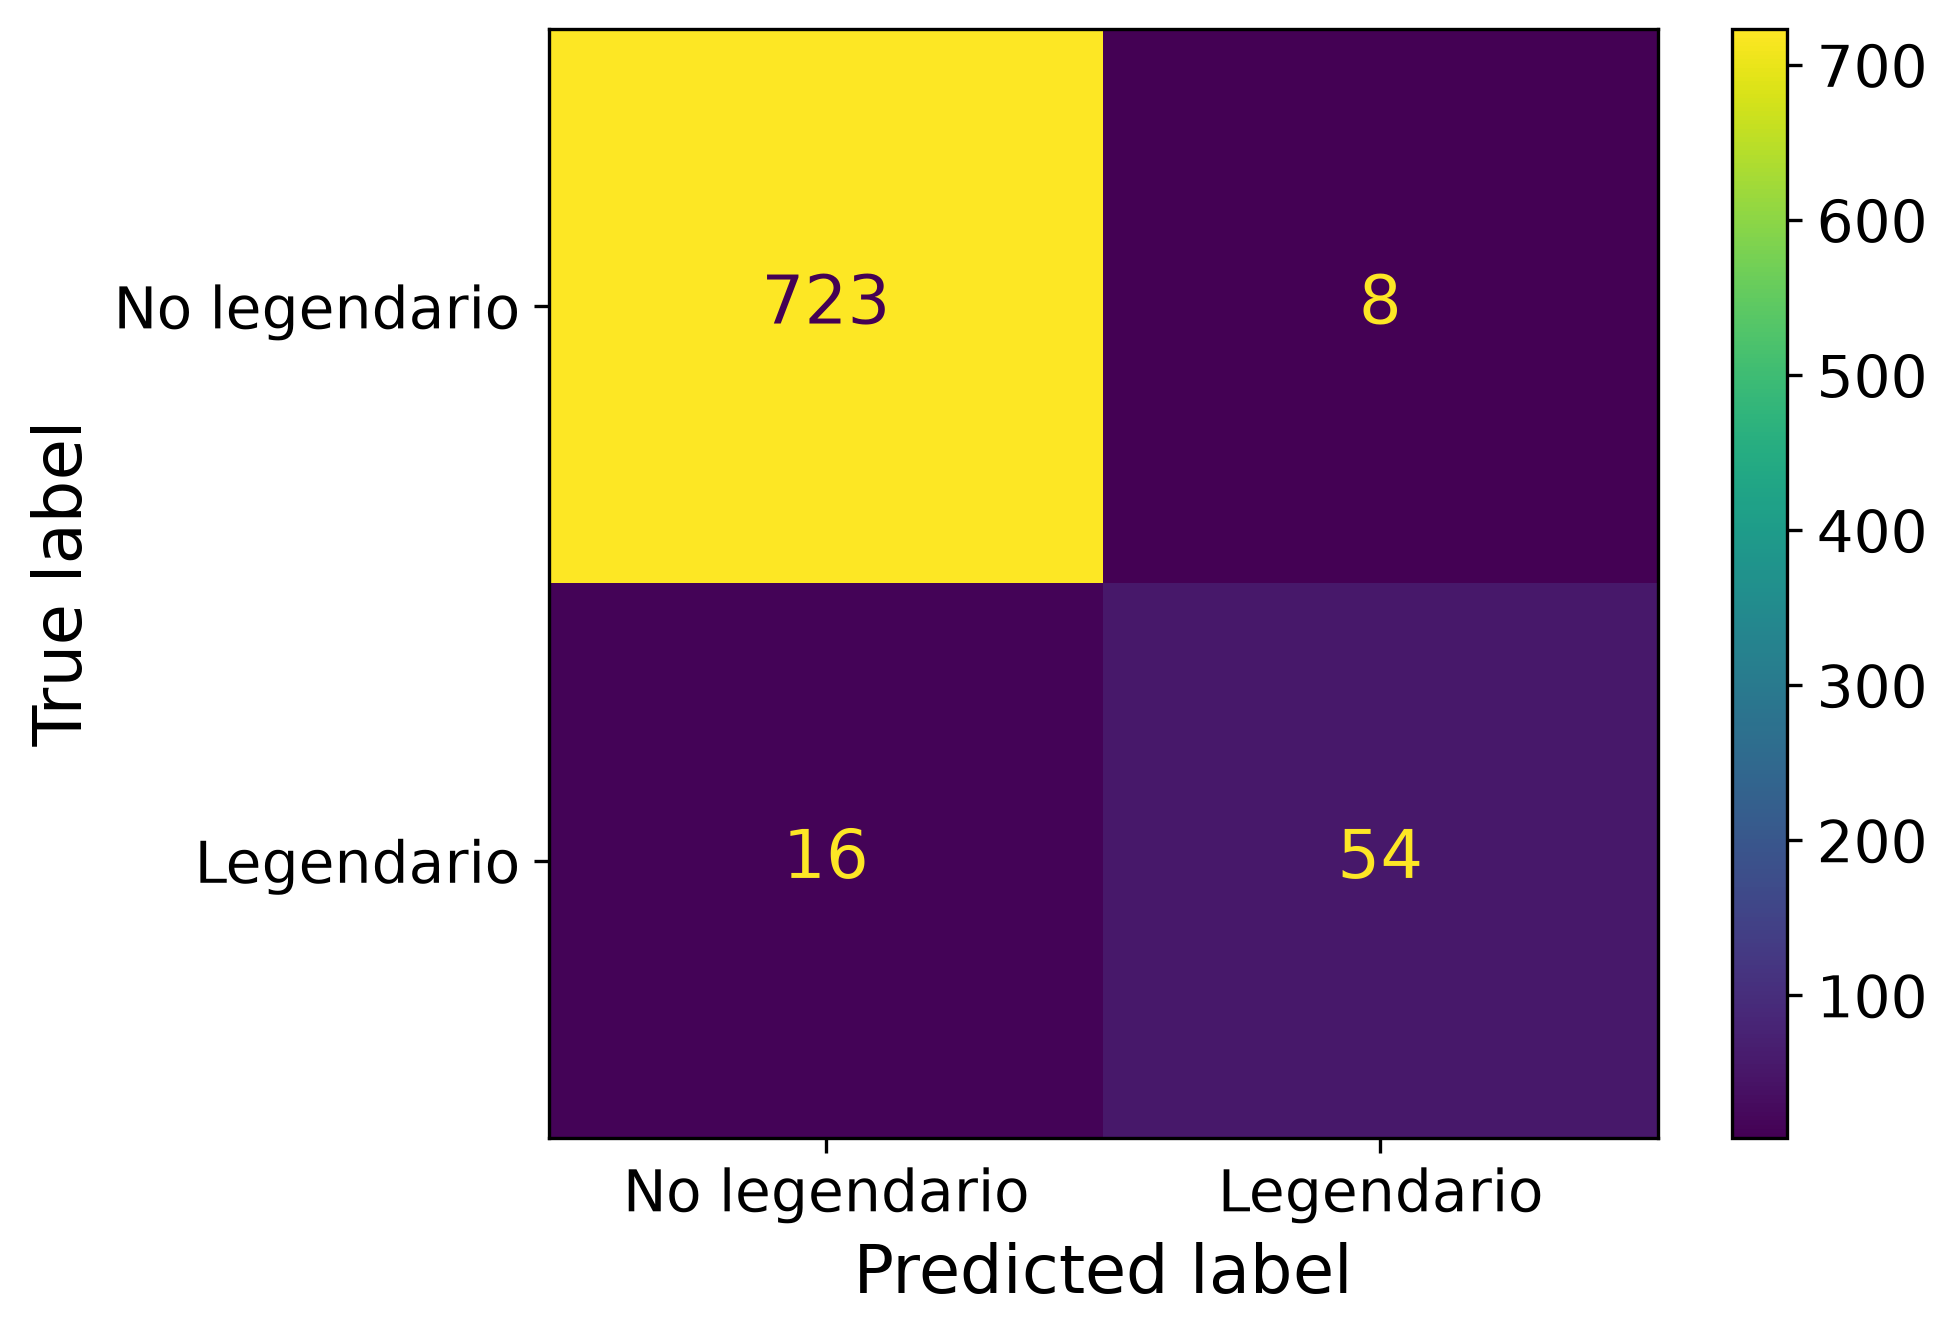

              precision    recall  f1-score   support

           0       0.98      0.99      0.98       731
           1       0.87      0.77      0.82        70

    accuracy                           0.97       801
   macro avg       0.92      0.88      0.90       801
weighted avg       0.97      0.97      0.97       801



In [123]:
ConfusionMatrixDisplay.from_predictions(target, y_pred,
                                        display_labels=['No legendario', 'Legendario'])
plt.show()

print(metrics.classification_report(target, y_pred))

Nota: Esta corresponde a la matriz de confusión con los datos de prueba.

# Parte 2: Experimento con el modelo